In [1]:
import http.client
import time
import urllib.error

import numpy as np
import matplotlib.pyplot as plt

from astropy.io import fits
from astropy.wcs import WCS
from astropy.table import Table
from astropy import units as u
from astropy.coordinates import SkyCoord

from astroquery.ipac.irsa import Irsa

from firefly_client import FireflyClient

# The time it takes to read SPHEREx files can exceed
# astropy's default timeout limit. Increase it.
from astropy.utils.data import conf
conf.remote_timeout = 120

In [2]:
ra_deg = 304.693508808
dec_deg = 42.4436872991

coord = SkyCoord(ra_deg, dec_deg, unit='deg')
search_radius = 1 * u.arcsec

In [3]:
Irsa.list_collections(servicetype='SIA', filter='spherex')

collection
object
spherex_dr1
spherex_dr1_cube
spherex_dr1_deep
spherex_qr3
spherex_qr3_deep


In [5]:
results = Irsa.query_sia(pos=(coord, search_radius), collection=['spherex_dr1', 'spherex_qr3'])
len(results)

443

In [6]:
results.colnames

['s_ra',
 's_dec',
 'facility_name',
 'instrument_name',
 'dataproduct_subtype',
 'calib_level',
 'dataproduct_type',
 'energy_bandpassname',
 'energy_emband',
 'obs_id',
 's_resolution',
 'em_min',
 'em_max',
 'em_res_power',
 'proposal_title',
 'access_url',
 'access_format',
 'access_estsize',
 't_exptime',
 's_region',
 'obs_collection',
 'obs_intent',
 'algorithm_name',
 'facility_keywords',
 'instrument_keywords',
 'environment_photometric',
 'proposal_id',
 'proposal_pi',
 'proposal_project',
 'target_name',
 'target_type',
 'target_standard',
 'target_moving',
 'target_keywords',
 'obs_release_date',
 's_xel1',
 's_xel2',
 's_pixel_scale',
 'position_timedependent',
 't_min',
 't_max',
 't_resolution',
 't_xel',
 'obs_publisher_did',
 's_fov',
 'em_xel',
 'pol_states',
 'pol_xel',
 'cloud_access',
 'o_ucd',
 'upload_row_id']

In [7]:
spectral_image_url = results['access_url'][0]
print(spectral_image_url)

https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/level2/2025W18_1B/l2b-v27-2026-196/1/level2_2025W18_1B_0074_2D1_spx_l2b-v27-2026-196.fits


In [8]:
# Max number of times to retry HTTP errors.
max_retries = 3
for attempt in range(max_retries):
    try:
        # Load the data, reading every extension into memory so that
        # hdulist stays usable after the file is closed.
        with fits.open(spectral_image_url, memmap=False) as hdulist:
            for hdu in hdulist:
                hdu.data
        break
    except (TimeoutError, urllib.error.HTTPError, http.client.IncompleteRead):
        if attempt == max_retries - 1:
            raise
        time.sleep(10 * (attempt + 1))

In [9]:
hdulist.info()

Filename: /home/steve/.cache/astropy/download/url/2edb0eda84f44a114b0a0118c29fe067/contents
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU       293   (2040, 2040)   float32   
  2  FLAGS         1 CompImageHDU    185   (2040, 2040)   int32   
  3  VARIANCE      1 ImageHDU       119   (2040, 2040)   float32   
  4  ZODI          1 ImageHDU       122   (2040, 2040)   float32   
  5  EPSF          1 BinTableHDU     56   441R x 11C   ['J', 'J', 'E', 'E', 'E', 'E', 'J', 'E', 'E', 'E', '1089D']   
  6  WCS-WAVE      1 BinTableHDU     22   1R x 3C   ['9J', '9J', '162E']   


In [11]:
fc = FireflyClient.make_client(url="https://irsa.ipac.caltech.edu/irsaviewer")

fc.reinit_viewer()

Opening in existing browser session.


[26210:26210:0100/000000.943393:ERROR:content/zygote/zygote_linux.cc:662] write: Broken pipe (32)
[1:1:0100/000000.944886:ERROR:content/zygote/zygote_main_linux.cc:197] Failed sending zygote boot message: Broken pipe (32)


{'success': True}

In [12]:
fc.show_fits_image(file_input=spectral_image_url,
             plot_id="spectral_image",
             Title="Spectral Image"
             )

{'success': True}

In [13]:
spectral_image_header = hdulist[1].header

keywords_to_print = ['EXTNAME', 'NAXIS1', 'NAXIS2', 'BUNIT', 'DETECTOR', 'OBSID', 'DATE', 'PSF_FWHM']

for keyword in keywords_to_print:
    value = spectral_image_header.get(keyword, 'Keyword not found')
    print(f"{keyword}: {value}")

EXTNAME: IMAGE
NAXIS1: 2040
NAXIS2: 2040
BUNIT: MJy / sr
DETECTOR: 1
OBSID: 2025W18_1B_0074_2
DATE: 2026-07-16T03:19:15.597
PSF_FWHM: 7.530770327317724


In [14]:
spectral_image_header['WCSNAME*']

WCSNAMEA= '0-based active pixel coordinates' / Coordinate system title          
WCSNAMEW= 'Approximated per-pixel wavelength and bandwidth' / WCS label         

In [15]:
wcs = WCS(spectral_image_header)
wcs

WCS Keywords

Number of WCS axes: 2
CTYPE : 'RA---TAN-SIP' 'DEC--TAN-SIP'
CUNIT : 'deg' 'deg'
CRVAL : 303.877766184 40.5489585415
CRPIX : 1020.5 1020.5
PC1_1 PC1_2  : -0.00161399858549 -0.000503359988208
PC2_1 PC2_2  : -0.000566313443671 0.00163301103545
CDELT : 1.0 1.0
NAXIS : 2040  2040

In [16]:
ra, dec = wcs.wcs.crval
x, y = wcs.world_to_pixel(SkyCoord(ra=ra, dec=dec, unit="deg"))
print(ra, dec, x, y)

303.877766184 40.5489585415 1019.0880637763953 1020.746373505631


In [17]:
# Load the Spectral WCS from the header.
# Note that we need to provide a reference to HDU List, which contains a lookup table.
spectral_wcs = WCS(header=hdulist["IMAGE"].header, fobj=hdulist, key="W")

INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                 [astropy.wcs.wcs]


In [18]:
# SIP distortions must be turned off for the spectral WCS.
spectral_wcs.sip = None

In [19]:
# The standard Astropy methods for converting pixel coordinates to world coordinates can also be used to obtain spectral coordinates.
# Take the pixel coordinates that we determined for the image center and resolve them to the wavelength and bandwidth for that pixel
wl, bw = spectral_wcs.pixel_to_world(x, y)
wl, bw

(<SpectralCoord 0.90416686 um>, <Quantity 0.02298403 um>)

In [20]:
# Read in the spectral image data.
spectral_image = hdulist["IMAGE"]
spectral_image_data = spectral_image.data

# Get arrays of pixel coordinates for the image.
(y, x) = np.indices(spectral_image.shape)

# Use the spectral WCS to convert these pixel coordinates to spectral coordinates.
spectral_coords = spectral_wcs.pixel_to_world(x, y)

# Break out the two spectral coordinates (wavelength and bandwidth) from the spectral coordinates, and print the results.
wavelength, bandwidth = spectral_coords
print("Wavelength: \n", wavelength)
print("Bandwidth: \n", bandwidth)

Wavelength: 
 [[1.12616599 1.12614512 1.12612426 ... 1.12623829 1.12625823 1.12627816]
 [1.12594346 1.1259226  1.12590174 ... 1.1260164  1.12603634 1.12605627]
 [1.12572094 1.12570008 1.12567922 ... 1.12579451 1.12581444 1.12583438]
 ...
 [0.74469219 0.74467621 0.74466023 ... 0.74529567 0.74531224 0.74532881]
 [0.74453702 0.74452105 0.74450508 ... 0.74514335 0.74515991 0.74517648]
 [0.74438184 0.74436589 0.74434993 ... 0.74499102 0.74500758 0.74502414]] um
Bandwidth: 
 [[0.02880928 0.02881236 0.02881544 ... 0.02953041 0.02952625 0.02952209]
 [0.02880678 0.02880985 0.02881291 ... 0.02952707 0.02952292 0.02951877]
 [0.02880427 0.02880733 0.02881039 ... 0.02952373 0.02951959 0.02951546]
 ...
 [0.01724998 0.01725043 0.01725087 ... 0.01568995 0.01568707 0.01568419]
 [0.01724339 0.01724384 0.0172443  ... 0.01567851 0.01567563 0.01567275]
 [0.0172368  0.01723726 0.01723772 ... 0.01566708 0.01566419 0.0156613 ]] um


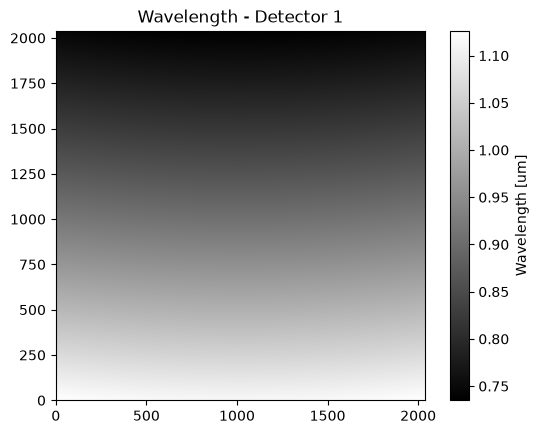

In [21]:
# Plot the wavelength as a greyscale color map across the image pixels.
plt.imshow(wavelength.value, origin='lower', cmap='gray')
plt.colorbar(label=f"Wavelength [{wavelength.unit}]")

detector = hdulist["IMAGE"].header["DETECTOR"]
plt.title(f"Wavelength - Detector {detector}")
plt.show()

In [22]:
spectral_image_header['L2 N_*']

HIERARCH L2 N_NONLINEAR = 0 / number of pixels flagged nonlinear                
HIERARCH L2 N_PERSIST = 23502 / number of pixels flagged persist                
HIERARCH L2 N_HOT =                    1 / number of pixels flagged hot         
HIERARCH L2 N_COLD = 1307 / number of pixels flagged cold                       
HIERARCH L2 N_TRAN_NB = 23511 / number of not bad transient pixels              
HIERARCH L2 N_PERS_NB = 23498 / number of persistence and not bad pixels        
HIERARCH L2 N_SOURCE = 4135535 / number of source flagged pixels                
HIERARCH L2 N_XTALK = 53262 / number of crosstalk flagged pixels                
HIERARCH L2 N_GHOST = 0 / number of ghost flagged pixels                        
HIERARCH L2 N_GHOST_FPA = 0 / number of ghost_fpa flagged pixels                
HIERARCH L2 N_GHOST_EXT = 0 / number of ghost_ext flagged pixels                
HIERARCH L2 N_BLOOM_NS = 0 / number of BLOOM flagged pixels not flagged SOURCE  
HIERARCH L2 N_SNOW_NS = 0 / 

In [23]:
flags_header = hdulist[2].header

keywords_to_print = ['EXTNAME', 'NAXIS1', 'NAXIS2', 'BUNIT']

for keyword in keywords_to_print:
    value = flags_header.get(keyword, 'Keyword not found')
    print(f"{keyword}: {value}")

EXTNAME: FLAGS
NAXIS1: 2040
NAXIS2: 2040
BUNIT: 


In [24]:
for key in flags_header['MSKN*']:
    bit = key[4:]
    print(f"{int(bit):2d}  {flags_header[key]:<13} {flags_header['MSKD' + bit]}")

 0  TRANSIENT     Transient detected during SUR
 1  OVERFLOW      Overflow detected during SUR
 2  SUR_ERROR     Error in onboard processing
 6  NONFUNC       Permanently unusable
 7  DICHROIC      Low efficiency due to dichroic
 9  MISSING_DATA  Onboard data lost
10  HOT           Hot pixel
11  COLD          Anomalously low signal
12  FULLSAMPLE    Pixel full sample history is available
14  PHANMISS      Phantom correction was not applied
15  NONLINEAR     Nonlinearity correction cannot be applied reliably
17  PERSIST       Persistent charge above threshold
19  OUTLIER       Pixel flagged by Detect Outliers
20  CROSSTALK     Pixel affected by crosstalk.
21  SOURCE        Pixel mapped to a known source
22  GHOST         Affected by a bright source inside the exposure
23  GHOST_FPA     Affected by a bright source on another detector
24  GHOST_EXT     Pixel affected by a bright source outside FOV
25  STREAK        Pixel affected by a streak
26  BLOOM         Pixel part of a bloom artifac

In [25]:
variance_header = hdulist[3].header

keywords_to_print = ['EXTNAME', 'NAXIS1', 'NAXIS2', 'BUNIT']

for keyword in keywords_to_print:
    value = variance_header.get(keyword, 'Keyword not found')
    print(f"{keyword}: {value}")

EXTNAME: VARIANCE
NAXIS1: 2040
NAXIS2: 2040
BUNIT: MJy2 / sr2


In [26]:
zodi_header = hdulist[4].header

keywords_to_print = ['EXTNAME', 'NAXIS1', 'NAXIS2', 'BUNIT']

for keyword in keywords_to_print:
    value = zodi_header.get(keyword, 'Keyword not found')
    print(f"{keyword}: {value}")

EXTNAME: ZODI
NAXIS1: 2040
NAXIS2: 2040
BUNIT: MJy / sr


In [27]:
psf_header = hdulist["EPSF"].header

keywords_to_print = ['EXTNAME', 'NAXIS2', 'DETECTOR', 'OVSMPX', 'OVSMPY']

for keyword in keywords_to_print:
    value = psf_header.get(keyword, 'Keyword not found')
    print(f"{keyword}: {value}")

EXTNAME: EPSF
NAXIS2: 441
DETECTOR: 1
OVSMPX: 5
OVSMPY: 5


In [28]:
wcs_wave_header = hdulist[6].header
wcs_wave_header

XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                  720 / length of dimension 1                          
NAXIS2  =                    1 / length of dimension 2                          
PCOUNT  =                    0 / number of group parameters                     
GCOUNT  =                    1 / number of groups                               
TFIELDS =                    3 / number of table fields                         
TTYPE1  = 'X       '                                                            
TFORM1  = '9J      '                                                            
TDIM1   = '(9)     '                                                            
TTYPE2  = 'Y       '                                                            
TFORM2  = '9J      '        

In [29]:
wcs_wave_table = Table(hdulist[6].data)

print("Number of rows:", len(wcs_wave_table))
print("Column names:", wcs_wave_table.colnames)

Number of rows: 1
Column names: ['X', 'Y', 'VALUES']


In [30]:
x_array      = wcs_wave_table["X"][0]
y_array      = wcs_wave_table["Y"][0]
wavelengths  = wcs_wave_table["VALUES"][0]

print("X:",  x_array)
print("Y:",y_array)
print("Dimensions of VALUES array:",  wavelengths.shape)

X: [   1  256  511  766 1021 1275 1530 1785 2040]
Y: [   1  256  511  766 1021 1275 1530 1785 2040]
Dimensions of VALUES array: (9, 9, 2)
